In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import re
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

df = pd.read_csv("fakenews.csv")

df["headline"] = df["headline"].fillna("").astype(str)
df["body_text"] = df["body_text"].fillna("").astype(str)
df["text"] = df["headline"] + " " + df["body_text"]

analyzer = SentimentIntensityAnalyzer()

print(df[["label", "headline", "body_text"]].head())

  label                                    headline  \
0  Real              Global economy faces recession   
1  Real   Earthquake hits Chittagong, panic spreads   
2  Fake  Breakthrough in Bangladesh's tech industry   
3  Fake     Dengue situation worsens in the country   
4  Real              New virus outbreak sparks fear   

                                           body_text  
0  The Prime Minister attended the inauguration c...  
1  Government sources state that an official anno...  
2  Local administration has visited the spot for ...  
3  The Prime Minister attended the inauguration c...  
4  Government sources state that an official anno...  


In [2]:
emotional_words = [
    "shocking", "outrageous", "terrifying", "horrific",
    "amazing", "disaster", "unbelievable", "evil",
    "urgent", "explosive", "devastating", "miracle",
    "disgrace", "crisis", "furious", "dangerous",
    "wonderful", "terrible", "hateful", "appalling"
]

opinion_words = [
    "obviously", "clearly", "undoubtedly", "fortunately",
    "unfortunately", "allegedly", "supposedly", "must",
    "should", "worst", "best"
]

def count_words(text):
    return re.findall(r"\b[a-zA-Z]+\b", str(text).lower())

def count_capital_words(text):
    return sum(
        1 for word in str(text).split()
        if len(word) > 1 and word.isupper()
    )

df["word_count"] = df["text"].apply(lambda x: len(count_words(x)))

df["emotional_word_count"] = df["text"].apply(
    lambda x: sum(word in emotional_words for word in count_words(x))
)

df["opinion_word_count"] = df["text"].apply(
    lambda x: sum(word in opinion_words for word in count_words(x))
)

df["exclamation_count"] = df["text"].str.count("!")
df["capital_word_count"] = df["text"].apply(count_capital_words)

scores = df["text"].apply(
    lambda x: analyzer.polarity_scores(x)
)

sentiment_df = pd.DataFrame(scores.tolist())

df["positive_score"] = sentiment_df["pos"]
df["negative_score"] = sentiment_df["neg"]
df["neutral_score"] = sentiment_df["neu"]
df["compound_score"] = sentiment_df["compound"]

df["sentiment_intensity"] = df["compound_score"].abs()

df["emotional_word_rate"] = (
    df["emotional_word_count"] / df["word_count"].clip(lower=1) * 100
)

df["opinion_word_rate"] = (
    df["opinion_word_count"] / df["word_count"].clip(lower=1) * 100
)

print(df[[
    "label", "sentiment_intensity", "emotional_word_rate",
    "opinion_word_rate", "exclamation_count", "capital_word_count"
]].head())

  label  sentiment_intensity  emotional_word_rate  opinion_word_rate  \
0  Real               0.4215                  0.0                0.0   
1  Real               0.5106                  0.0                0.0   
2  Fake               0.0000                  0.0                0.0   
3  Fake               0.4767                  0.0                0.0   
4  Real               0.4939                  0.0                0.0   

   exclamation_count  capital_word_count  
0                  0                   0  
1                  0                   0  
2                  0                   0  
3                  0                   0  
4                  0                   0  


In [3]:
intensity_limit = df["sentiment_intensity"].median()
emotion_limit = df["emotional_word_rate"].median()

df["writing_style"] = (
    (df["sentiment_intensity"] >= intensity_limit) &
    (df["emotional_word_rate"] >= emotion_limit)
).map({
    True: "Emotionally Charged",
    False: "Relatively Neutral"
})

print(df[["label", "writing_style"]].head(10))

print("\nWriting Style Distribution:")
print(pd.crosstab(df["label"], df["writing_style"]))

  label        writing_style
0  Real  Emotionally Charged
1  Real  Emotionally Charged
2  Fake   Relatively Neutral
3  Fake  Emotionally Charged
4  Real  Emotionally Charged
5  Fake  Emotionally Charged
6  Fake  Emotionally Charged
7  Real  Emotionally Charged
8  Fake  Emotionally Charged
9  Real   Relatively Neutral

Writing Style Distribution:
writing_style  Emotionally Charged  Relatively Neutral
label                                                 
Fake                           542                 568
Real                           580                 522


In [4]:
metrics_comparison = df.groupby("label").agg(
    average_sentiment_intensity=("sentiment_intensity", "mean"),
    average_positive_score=("positive_score", "mean"),
    average_negative_score=("negative_score", "mean"),
    average_neutral_score=("neutral_score", "mean"),
    average_emotional_word_rate=("emotional_word_rate", "mean"),
    average_opinion_word_rate=("opinion_word_rate", "mean"),
    average_exclamations=("exclamation_count", "mean"),
    average_capital_words=("capital_word_count", "mean")
).round(3)

print(metrics_comparison)

       average_sentiment_intensity  average_positive_score  \
label                                                        
Fake                         0.320                   0.067   
Real                         0.333                   0.071   

       average_negative_score  average_neutral_score  \
label                                                  
Fake                    0.129                  0.804   
Real                    0.127                  0.802   

       average_emotional_word_rate  average_opinion_word_rate  \
label                                                           
Fake                           0.0                        0.0   
Real                           0.0                        0.0   

       average_exclamations  average_capital_words  
label                                               
Fake                    0.0                    0.0  
Real                    0.0                    0.0  


writing_style  Emotionally Charged  Relatively Neutral
label                                                 
Fake                         48.83               51.17
Real                         52.63               47.37


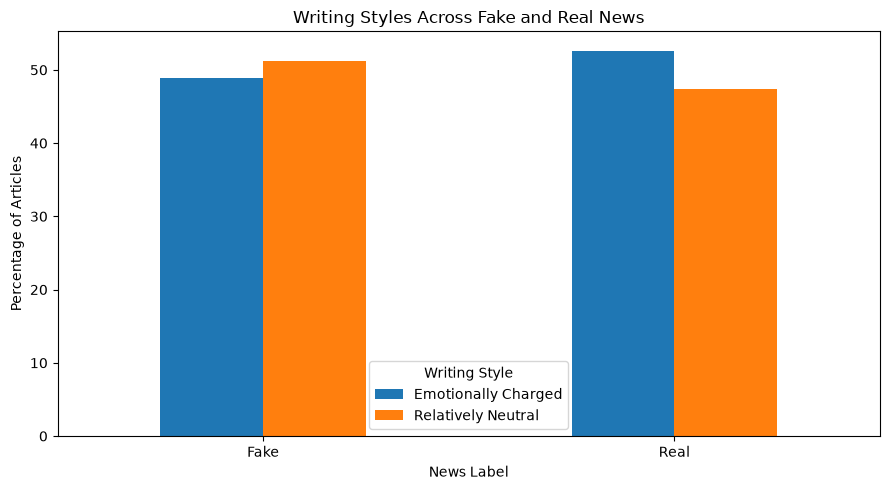

In [5]:
style_distribution = pd.crosstab(
    df["label"],
    df["writing_style"],
    normalize="index"
) * 100

print(style_distribution.round(2))

style_distribution.plot(kind="bar", figsize=(9, 5))

plt.title("Writing Styles Across Fake and Real News")
plt.xlabel("News Label")
plt.ylabel("Percentage of Articles")
plt.xticks(rotation=0)
plt.legend(title="Writing Style")
plt.tight_layout()
plt.show()

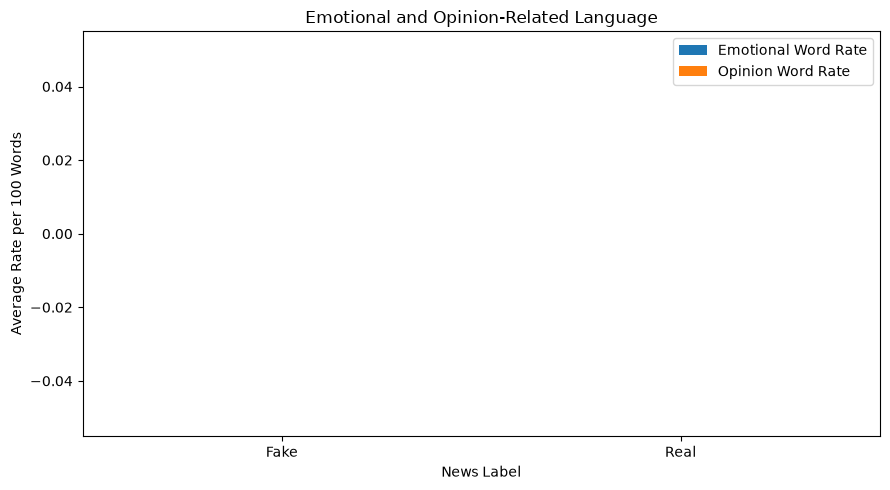

In [6]:
metrics_comparison[[
    "average_emotional_word_rate",
    "average_opinion_word_rate"
]].plot(kind="bar", figsize=(9, 5))

plt.title("Emotional and Opinion-Related Language")
plt.xlabel("News Label")
plt.ylabel("Average Rate per 100 Words")
plt.xticks(rotation=0)
plt.legend(["Emotional Word Rate", "Opinion Word Rate"])
plt.tight_layout()
plt.show()

In [7]:
df.to_csv("T35_writing_style_analysis.csv", index=False)
metrics_comparison.to_csv("T35_linguistic_metrics_comparison.csv")
style_distribution.to_csv("T35_writing_style_distribution.csv")